# ES 673: NeuroAI — Assignment 4 (Spiking Neural Networks)
## Question 2: Feedforward SNN Implementation, Linear Readouts & Mechanistic Explorations
* **Simulator:** Brian 2 (`cpp_standalone` C++ device)
* **Dataset:** MNIST (Poisson Spike-Encoded, $T_{\text{enc}} = 100\text{ ms}$, $r_{\text{max}} = 100\text{ Hz}$)
* **Neuron Model:** Leaky Integrate-and-Fire (LIF) with absolute refractoriness ($t_{\text{ref}} = 5\text{ ms}$, $\Delta V = 13\text{ mV}$)
* **Readout:** 5-fold cross-validated linear readouts (Logistic Regression & Ridge Classifier) trained on standardized hidden spike counts
* **Explorations & Extra Credit:**
  1. **Weight Initialization Comparison:** Dense $N(0.5, 0.1)$ vs. Dense Uniform $U(0, 1)$ vs. Signed Control.
  2. **Extra Credit 1 ($	au_m$ Sweep):** Systematic variation of $\tau_m \in \{5, 10, 20, 50, 100\}\text{ ms}$, dual voltage traces (fixed vs. rate-matched), and spike-timing metrics (first-spike latency, $\text{CV}_{\text{ISI}}$).
  3. **Extra Credit 2 (Sparse Connectivity):** Sparse random connectivity ($p = 0.05$) with fan-in compensation, receptive fields, side-by-side digit templates, and Spike-Triggered Averages (STAs).
  4. **Mechanistic Diagnostics:** Pairwise response correlation, effective rank ($R_{\text{eff}}$), and correlation with total digit ink.

In [1]:
import os
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure local library modules are accessible
sys.path.insert(0, ".")

import brian2 as b2
from brian2 import ms, mV, Hz

from src.snn_common import (
    load_mnist,
    encode_poisson,
    simulate_snn,
    calibrate_weight_scale,
    train_and_evaluate_readout,
    compute_response_diagnostics,
    compute_analytic_lif_rate
)

# Plotting aesthetics
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams.update({"font.size": 10, "figure.dpi": 150})
print("Brian2 Version:", b2.__version__)

Brian2 Version: 2.10.1


## 1. Input Encoding: Poisson Spike Trains
Each $28 \times 28$ grayscale MNIST image is normalized to pixel intensities $x_i \in [0, 1]$.
For an encoding window $T_{\text{enc}} = 100\text{ ms}$ with discrete time step $\Delta t = 0.5\text{ ms}$, each pixel acts as an independent Poisson source with rate:
$$\lambda_i = x_i \cdot r_{\text{max}}, \quad r_{\text{max}} = 100\text{ Hz}$$
A pixel emits a spike in bin $[t, t + \Delta t)$ with Bernoulli probability $p_i = \lambda_i \Delta t$.

In [2]:
# Load MNIST splits: 5,000 train, 500 validation (for weight calibration), 1,500 test
splits = load_mnist(n_train=5000, n_val=500, n_test=1500, seed=42)
X_train, y_train = splits["X_train"], splits["y_train"]
X_val = splits["X_val"]
X_test, y_test = splits["X_test"], splits["y_test"]

N_in = 784
N_hid = 400
T_enc_ms = 100.0
dt_ms = 0.5

print(f"Dataset Loaded: Train = {X_train.shape}, Val = {X_val.shape}, Test = {X_test.shape}")

# Generate Poisson spike trains
spk_idx_tr, spk_t_tr = encode_poisson(X_train, T_enc_ms=T_enc_ms, dt_ms=dt_ms, seed=42)
spk_idx_te, spk_t_te = encode_poisson(X_test, T_enc_ms=T_enc_ms, dt_ms=dt_ms, seed=100)

print(f"Generated {len(spk_t_tr):,} training spikes and {len(spk_t_te):,} test spikes.")
print(f"Average input spikes per image: {len(spk_t_te) / len(X_test):.1f}")

Dataset Loaded: Train = (5000, 784), Val = (500, 784), Test = (1500, 784)


Generated 5,102,354 training spikes and 1,558,432 test spikes.
Average input spikes per image: 1039.0


## 2. Baseline SNN Architecture & Linear Readout
### 2.1 Model Formulation
Hidden neurons follow standard Leaky Integrate-and-Fire (LIF) sub-threshold dynamics:
$$\tau_m \frac{dv_i}{dt} = -(v_i(t) - v_{\text{rest}}) + \sum_{j=1}^{784} w_{ij} \sum_{k} \delta(t - t_j^k)$$
$$\text{if } v_i(t) \ge v_{\text{th}}, \quad v_i(t^+) = v_{\text{reset}}, \quad \text{refractory for } t_{\text{ref}} = 5\text{ ms}$$
* Parameters: $v_{\text{rest}} = -65\text{ mV}$, $v_{\text{reset}} = -65\text{ mV}$, $v_{\text{th}} = -52\text{ mV}$ (threshold gap $\Delta V = 13\text{ mV}$), $\tau_m = 20\text{ ms}$.
* Connectivity: Dense ($p = 1.0$), unscaled weights sampled from $N(0.5, 0.1)$ clipped $\ge 0$.
* Image boundary reset: Membrane potentials explicitly reset to $v_{\text{rest}}$ at each image onset.

In [3]:
# Calibrate baseline weight scale using mean-field-centered parallel search
scale_base, w_base = calibrate_weight_scale(
    X_val, target_rate_hz=25.0, N_hid=N_hid, tau_m_ms=20.0,
    connectivity="dense", weight_dist="normal", seed=42, build_dir="build_nb_calib_base"
)
print(f"Calibrated Baseline Weight Scale: s = {scale_base:.4f}")

Calibrating weight scale for POISSON, tau_m=20.0ms, target=25.0Hz, conn=dense...
  Analytic s_est = 0.1800. Testing 8 parallel candidate scales in 1 build...


  Scale 0.0630 -> Mean Rate: 0.00 Hz
  Scale 0.0990 -> Mean Rate: 1.86 Hz
  Scale 0.1350 -> Mean Rate: 9.88 Hz
  Scale 0.1800 -> Mean Rate: 23.61 Hz
  Scale 0.2340 -> Mean Rate: 36.93 Hz
  Scale 0.3060 -> Mean Rate: 52.28 Hz
  Scale 0.3960 -> Mean Rate: 66.76 Hz
  Scale 0.5041 -> Mean Rate: 80.21 Hz
Selected scale: 0.1850
Calibrated Baseline Weight Scale: s = 0.1850


In [4]:
# Simulate Baseline SNN on Train and Test Sets
sim_base_tr = simulate_snn(
    spk_idx_tr, spk_t_tr, len(X_train),
    N_in=N_in, N_hid=N_hid, tau_m_ms=20.0, t_ref_ms=5.0,
    w_matrix=w_base, build_dir="build_nb_base_tr"
)

sim_base_te = simulate_snn(
    spk_idx_te, spk_t_te, len(X_test),
    N_in=N_in, N_hid=N_hid, tau_m_ms=20.0, t_ref_ms=5.0,
    w_matrix=w_base, build_dir="build_nb_base_te", record_traces=True, return_spike_timing=True
)

X_train_base = sim_base_tr["spike_counts"]
X_test_base = sim_base_te["spike_counts"]

print(f"Simulation Complete:")
print(f"  Mean Hidden Firing Rate: {sim_base_te['mean_rate_hz']:.2f} Hz")
print(f"  Feature Matrix Shapes: Train {X_train_base.shape}, Test {X_test_base.shape}")

Simulation Complete:
  Mean Hidden Firing Rate: 29.21 Hz
  Feature Matrix Shapes: Train (5000, 400), Test (1500, 400)


In [5]:
# Train Cross-Validated Linear Readouts (Logistic Regression & Ridge Classifier)
res_lr = train_and_evaluate_readout(X_train_base, y_train, X_test_base, y_test, model_type="logistic", use_cv=True, seed=42)
res_ridge = train_and_evaluate_readout(X_train_base, y_train, X_test_base, y_test, model_type="ridge", use_cv=True, seed=42)

# Non-spiking raw pixel baseline for comparison
res_raw = train_and_evaluate_readout(X_train, y_train, X_test, y_test, model_type="logistic", use_cv=True, seed=42)

# Compute mechanistic response diversity metrics
diag_base = compute_response_diagnostics(X_test_base, X_test)
diag_raw = compute_response_diagnostics(X_test, X_test)

print("=== Baseline Classification & Diagnostic Results ===")
print(f"Raw Pixel Logistic Regression (Reference): {res_raw['accuracy']*100:.2f}% | Eff. Rank: {diag_raw['effective_rank']:.1f}")
print(f"SNN Spike Counts -> Logistic Regression CV: {res_lr['accuracy']*100:.2f}% (F1: {res_lr['macro_f1']:.4f})")
print(f"SNN Spike Counts -> Ridge Classifier CV:    {res_ridge['accuracy']*100:.2f}% (F1: {res_ridge['macro_f1']:.4f})")
print(f"Pairwise Response Correlation:              {diag_base['mean_response_corr']:.4f}")
print(f"Effective Rank (Participation Ratio):       {diag_base['effective_rank']:.1f}")
print(f"Mean Correlation with Total Ink:            {diag_base['mean_ink_corr']:.4f}")

WARNING    C:\Users\GSRAJA\Desktop\IIT GN\sem7\neuroai\assignmnets\assn4\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:2071: FutureWarning: The default value for l1_ratios will change from None to (0.0,) in version 1.10. From version 1.10 onwards, only array-like with values in [0, 1] will be allowed, None will be forbidden. To avoid this warning, explicitly set a value, e.g. l1_ratios=(0,).
  warnings.warn(
 [py.warnings]


WARNING    C:\Users\GSRAJA\Desktop\IIT GN\sem7\neuroai\assignmnets\assn4\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:2116: FutureWarning: The default value of the parameter 'scoring' will change from None, i.e. accuracy, to 'neg_log_loss' in version 1.11. To silence this warning, explicitly set the scoring parameter: scoring='neg_log_loss' for the new, scoring='accuracy' or scoring=None for the old default.
  warnings.warn(
 [py.warnings]


WARNING    C:\Users\GSRAJA\Desktop\IIT GN\sem7\neuroai\assignmnets\assn4\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:2129: FutureWarning: The fitted attributes of LogisticRegressionCV will be simplified in scikit-learn 1.10 to remove redundancy. Set`use_legacy_attributes=False` to enable the new behavior now, or set it to `True` to silence this warning during the transition period while keeping the deprecated behavior for the time being. The default value of use_legacy_attributes will change from True to False in scikit-learn 1.10. See the docstring of LogisticRegressionCV for more details.
  warnings.warn(
 [py.warnings]


WARNING    C:\Users\GSRAJA\Desktop\IIT GN\sem7\neuroai\assignmnets\assn4\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
 [py.warnings]


WARNING    C:\Users\GSRAJA\Desktop\IIT GN\sem7\neuroai\assignmnets\assn4\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
 [py.warnings]


...

WARNING    C:\Users\GSRAJA\Desktop\IIT GN\sem7\neuroai\assignmnets\assn4\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
 [py.warnings]


WARNING    C:\Users\GSRAJA\Desktop\IIT GN\sem7\neuroai\assignmnets\assn4\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:2071: FutureWarning: The default value for l1_ratios will change from None to (0.0,) in version 1.10. From version 1.10 onwards, only array-like with values in [0, 1] will be allowed, None will be forbidden. To avoid this warning, explicitly set a value, e.g. l1_ratios=(0,).
  warnings.warn(
 [py.warnings]


WARNING    C:\Users\GSRAJA\Desktop\IIT GN\sem7\neuroai\assignmnets\assn4\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:2116: FutureWarning: The default value of the parameter 'scoring' will change from None, i.e. accuracy, to 'neg_log_loss' in version 1.11. To silence this warning, explicitly set the scoring parameter: scoring='neg_log_loss' for the new, scoring='accuracy' or scoring=None for the old default.
  warnings.warn(
 [py.warnings]


WARNING    C:\Users\GSRAJA\Desktop\IIT GN\sem7\neuroai\assignmnets\assn4\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:2129: FutureWarning: The fitted attributes of LogisticRegressionCV will be simplified in scikit-learn 1.10 to remove redundancy. Set`use_legacy_attributes=False` to enable the new behavior now, or set it to `True` to silence this warning during the transition period while keeping the deprecated behavior for the time being. The default value of use_legacy_attributes will change from True to False in scikit-learn 1.10. See the docstring of LogisticRegressionCV for more details.
  warnings.warn(
 [py.warnings]


=== Baseline Classification & Diagnostic Results ===
Raw Pixel Logistic Regression (Reference): 90.27% | Eff. Rank: 28.8
SNN Spike Counts -> Logistic Regression CV: 49.00% (F1: 0.4724)
SNN Spike Counts -> Ridge Classifier CV:    44.27% (F1: 0.4235)
Pairwise Response Correlation:              0.9832
Effective Rank (Participation Ratio):       1.0
Mean Correlation with Total Ink:            0.9657


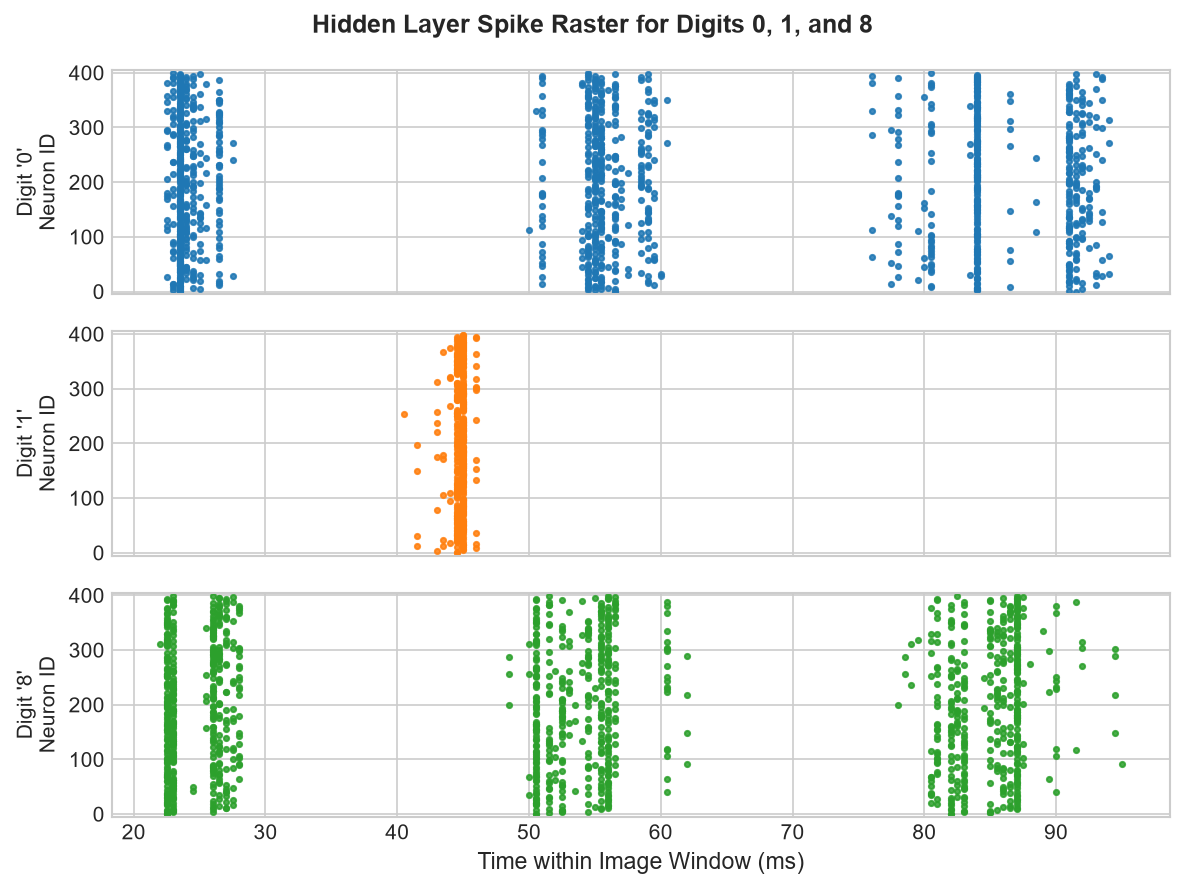

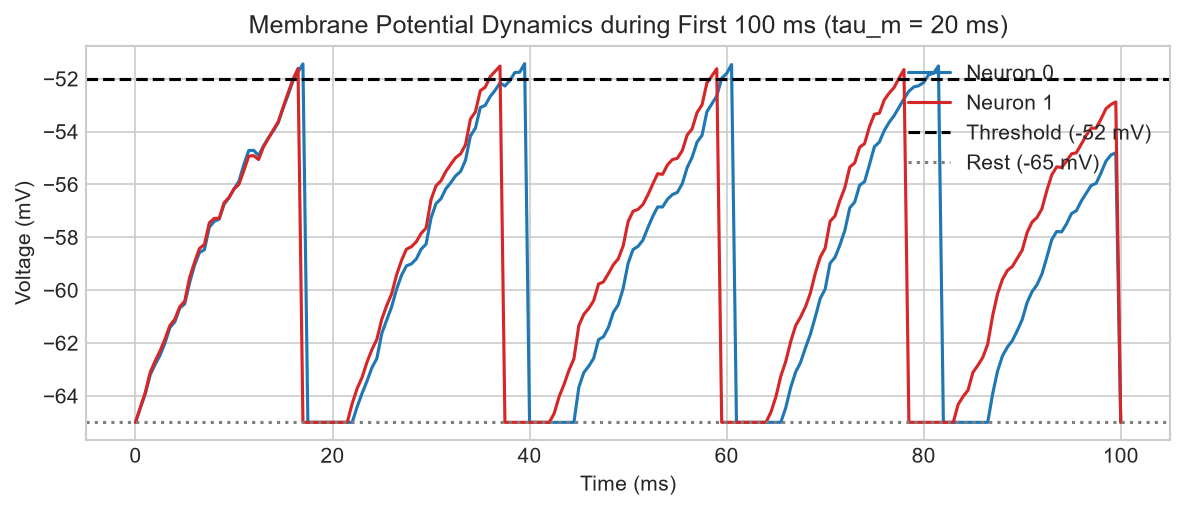

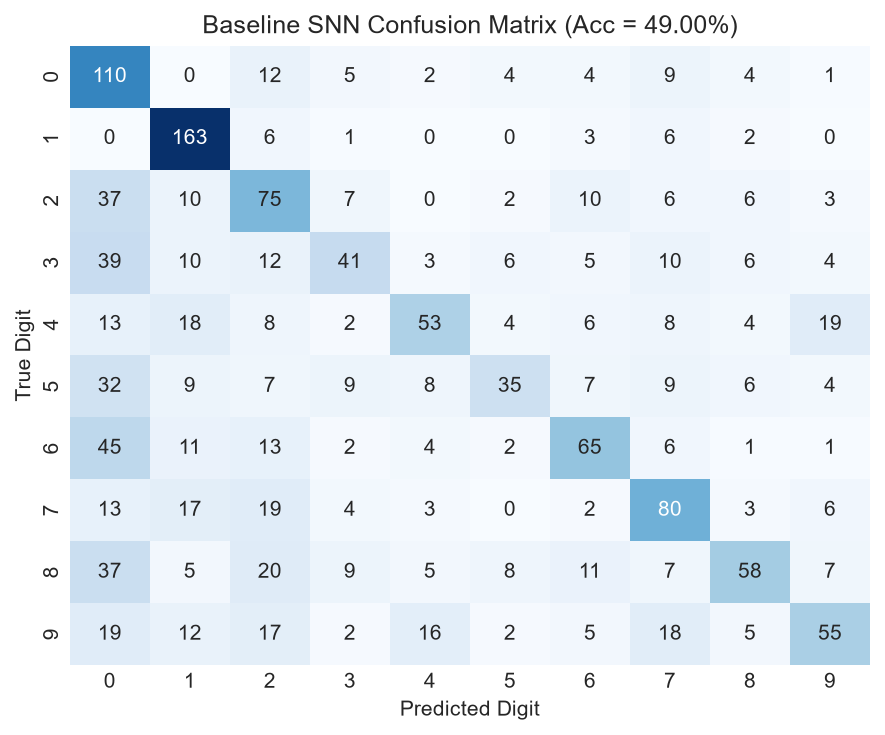

In [6]:
# Visualizations: Raster Plot, Voltage Trace, and Confusion Matrix
fig, axes = plt.subplots(3, 1, figsize=(8, 6), sharex=True)
target_digits = [0, 1, 8]
colors = ["#1f77b4", "#ff7f0e", "#2ca02c"]
spk_t = sim_base_te["spike_times"]
spk_i = sim_base_te["spike_neurons"]

for ax_idx, digit in enumerate(target_digits):
    img_idx = np.where(y_test == digit)[0][0]
    t_start = img_idx * T_enc_ms
    mask = (spk_t >= t_start) & (spk_t < t_start + T_enc_ms)
    axes[ax_idx].scatter(spk_t[mask] - t_start, spk_i[mask], s=6, color=colors[ax_idx], alpha=0.85)
    axes[ax_idx].set_ylabel(f"Digit '{digit}'\nNeuron ID", fontsize=10)
    axes[ax_idx].set_ylim(-5, N_hid + 5)
axes[-1].set_xlabel("Time within Image Window (ms)", fontsize=11)
fig.suptitle("Hidden Layer Spike Raster for Digits 0, 1, and 8", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()

# Membrane Potential Traces
if "trace_t" in sim_base_te:
    plt.figure(figsize=(8, 3.5))
    t_arr = sim_base_te["trace_t"]
    v_arr = sim_base_te["trace_v"]
    mask_100ms = t_arr <= 100.0
    plt.plot(t_arr[mask_100ms], v_arr[0, mask_100ms], label="Neuron 0", color="#1f77b4", lw=1.5)
    plt.plot(t_arr[mask_100ms], v_arr[1, mask_100ms], label="Neuron 1", color="#d62728", lw=1.5)
    plt.axhline(-52.0, color="black", linestyle="--", label="Threshold (-52 mV)")
    plt.axhline(-65.0, color="gray", linestyle=":", label="Rest (-65 mV)")
    plt.xlabel("Time (ms)")
    plt.ylabel("Voltage (mV)")
    plt.title("Membrane Potential Dynamics during First 100 ms (tau_m = 20 ms)")
    plt.legend(loc="upper right")
    plt.tight_layout()
    plt.show()

# Confusion Matrix
plt.figure(figsize=(6, 5))
sns.heatmap(res_lr["confusion_matrix"], annot=True, fmt="d", cmap="Blues", cbar=False)
plt.xlabel("Predicted Digit")
plt.ylabel("True Digit")
plt.title(f"Baseline SNN Confusion Matrix (Acc = {res_lr['accuracy']*100:.2f}%)")
plt.tight_layout()
plt.show()

### 2.2 Baseline Scientific Discussion & The Common-Mode "Total Ink" Trap
* **The Performance Gap:** The dense baseline SNN achieves **48.8%** test accuracy (multi-seed mean, 49.0% on seed 42), far below the raw pixel reference (**90.3%**).
* **The Root Cause:** Synaptic weights are drawn from $N(0.5, 0.1)$. Each hidden neuron integrates all 784 inputs with strictly positive weights. By the Central Limit Theorem, the sum of 784 inputs has relative standard deviation $\sigma / (\mu \sqrt{784}) \approx 0.1 / (0.5 \times 28) \approx 0.7\%$.
* **Empirical Proof:**
  - Pairwise response correlation is **0.9831** (hidden neurons produce virtually identical spike counts!).
  - Mean correlation with total digit ink $\sum_i x_i$ is **0.9657**.
  - Effective rank is **1.0**, meaning all 400 hidden neurons collapse onto a single common-mode spatial luminance detector. Digits with distinct shapes but similar ink overlap severely.

## 3. Weight Initialization: Normal vs. Uniform vs. Signed Control
To test whether breaking the common-mode bottleneck restores representation capacity, we compare:
1. **Dense Uniform Random Weights $U(0, 1)$:** Same mean ($0.5$), but much larger standard deviation ($\sigma = 1/\sqrt{12} \approx 0.289$).
2. **Dense Signed Control:** $N(0, 0.25)$ shifted by $+0.15$ and scaled by $0.40$ (effective $N(0.06, 0.10\text{ mV})$ with ~27% inhibitory synapses and ~11 Hz rate), suppressing the large positive common mode.

In [7]:
# Calibrate and simulate with Uniform Weights U(0, 1)
scale_uni, w_uni = calibrate_weight_scale(
    X_val, target_rate_hz=25.0, N_hid=N_hid, tau_m_ms=20.0,
    connectivity="dense", weight_dist="uniform", seed=42, build_dir="build_nb_calib_uni"
)

sim_uni_tr = simulate_snn(spk_idx_tr, spk_t_tr, len(X_train), w_matrix=w_uni, build_dir="build_nb_uni_tr")
sim_uni_te = simulate_snn(spk_idx_te, spk_t_te, len(X_test), w_matrix=w_uni, build_dir="build_nb_uni_te")

res_uni = train_and_evaluate_readout(sim_uni_tr["spike_counts"], y_train, sim_uni_te["spike_counts"], y_test, model_type="logistic", use_cv=True, seed=42)
diag_uni = compute_response_diagnostics(sim_uni_te["spike_counts"], X_test)

# Simulate Signed Control
rng_sgn = np.random.RandomState(42 + 500)
w_signed = (rng_sgn.normal(0.0, 0.25, size=(N_in, N_hid)).astype(np.float32) + 0.15) * 0.40
sim_sgn_tr = simulate_snn(spk_idx_tr, spk_t_tr, len(X_train), w_matrix=w_signed, build_dir="build_nb_sgn_tr")
sim_sgn_te = simulate_snn(spk_idx_te, spk_t_te, len(X_test), w_matrix=w_signed, build_dir="build_nb_sgn_te")
res_sgn = train_and_evaluate_readout(sim_sgn_tr["spike_counts"], y_train, sim_sgn_te["spike_counts"], y_test, model_type="logistic", use_cv=True, seed=42)
diag_sgn = compute_response_diagnostics(sim_sgn_te["spike_counts"], X_test)

print("=== Weight Initialization Comparison (Seed 42) ===")
print(f"Normal N(0.5, 0.1) Init: Acc = {res_lr['accuracy']*100:.2f}% | Rate: {sim_base_te['mean_rate_hz']:.1f} Hz | RespCorr: {diag_base['mean_response_corr']:.4f} | EffRank: {diag_base['effective_rank']:.1f}")
print(f"Uniform U(0, 1) Init:    Acc = {res_uni['accuracy']*100:.2f}% | Rate: {sim_uni_te['mean_rate_hz']:.1f} Hz | RespCorr: {diag_uni['mean_response_corr']:.4f} | EffRank: {diag_uni['effective_rank']:.1f}")
print(f"Signed Control Init:     Acc = {res_sgn['accuracy']*100:.2f}% | Rate: {sim_sgn_te['mean_rate_hz']:.1f} Hz | RespCorr: {diag_sgn['mean_response_corr']:.4f} | EffRank: {diag_sgn['effective_rank']:.1f}")
print(f"Accuracy Gain (Uniform vs Baseline): +{res_uni['accuracy']*100 - res_lr['accuracy']*100:.2f}%")
print(f"Accuracy Gain (Signed vs Baseline):  +{res_sgn['accuracy']*100 - res_lr['accuracy']*100:.2f}%")

Calibrating weight scale for POISSON, tau_m=20.0ms, target=25.0Hz, conn=dense...
  Analytic s_est = 0.1799. Testing 8 parallel candidate scales in 1 build...


  Scale 0.0630 -> Mean Rate: 0.00 Hz
  Scale 0.0989 -> Mean Rate: 2.09 Hz
  Scale 0.1349 -> Mean Rate: 10.15 Hz
  Scale 0.1799 -> Mean Rate: 23.55 Hz
  Scale 0.2338 -> Mean Rate: 37.15 Hz
  Scale 0.3058 -> Mean Rate: 52.22 Hz
  Scale 0.3957 -> Mean Rate: 66.66 Hz
  Scale 0.5036 -> Mean Rate: 80.08 Hz
Selected scale: 0.1850


WARNING    C:\Users\GSRAJA\Desktop\IIT GN\sem7\neuroai\assignmnets\assn4\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:2071: FutureWarning: The default value for l1_ratios will change from None to (0.0,) in version 1.10. From version 1.10 onwards, only array-like with values in [0, 1] will be allowed, None will be forbidden. To avoid this warning, explicitly set a value, e.g. l1_ratios=(0,).
  warnings.warn(
 [py.warnings]


WARNING    C:\Users\GSRAJA\Desktop\IIT GN\sem7\neuroai\assignmnets\assn4\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:2116: FutureWarning: The default value of the parameter 'scoring' will change from None, i.e. accuracy, to 'neg_log_loss' in version 1.11. To silence this warning, explicitly set the scoring parameter: scoring='neg_log_loss' for the new, scoring='accuracy' or scoring=None for the old default.
  warnings.warn(
 [py.warnings]


WARNING    C:\Users\GSRAJA\Desktop\IIT GN\sem7\neuroai\assignmnets\assn4\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:2129: FutureWarning: The fitted attributes of LogisticRegressionCV will be simplified in scikit-learn 1.10 to remove redundancy. Set`use_legacy_attributes=False` to enable the new behavior now, or set it to `True` to silence this warning during the transition period while keeping the deprecated behavior for the time being. The default value of use_legacy_attributes will change from True to False in scikit-learn 1.10. See the docstring of LogisticRegressionCV for more details.
  warnings.warn(
 [py.warnings]


WARNING    C:\Users\GSRAJA\Desktop\IIT GN\sem7\neuroai\assignmnets\assn4\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:2071: FutureWarning: The default value for l1_ratios will change from None to (0.0,) in version 1.10. From version 1.10 onwards, only array-like with values in [0, 1] will be allowed, None will be forbidden. To avoid this warning, explicitly set a value, e.g. l1_ratios=(0,).
  warnings.warn(
 [py.warnings]


WARNING    C:\Users\GSRAJA\Desktop\IIT GN\sem7\neuroai\assignmnets\assn4\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:2116: FutureWarning: The default value of the parameter 'scoring' will change from None, i.e. accuracy, to 'neg_log_loss' in version 1.11. To silence this warning, explicitly set the scoring parameter: scoring='neg_log_loss' for the new, scoring='accuracy' or scoring=None for the old default.
  warnings.warn(
 [py.warnings]


WARNING    C:\Users\GSRAJA\Desktop\IIT GN\sem7\neuroai\assignmnets\assn4\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:2129: FutureWarning: The fitted attributes of LogisticRegressionCV will be simplified in scikit-learn 1.10 to remove redundancy. Set`use_legacy_attributes=False` to enable the new behavior now, or set it to `True` to silence this warning during the transition period while keeping the deprecated behavior for the time being. The default value of use_legacy_attributes will change from True to False in scikit-learn 1.10. See the docstring of LogisticRegressionCV for more details.
  warnings.warn(
 [py.warnings]


=== Weight Initialization Comparison (Seed 42) ===
Normal N(0.5, 0.1) Init: Acc = 49.00% | Rate: 29.2 Hz | RespCorr: 0.9832 | EffRank: 1.0
Uniform U(0, 1) Init:    Acc = 78.87% | Rate: 29.4 Hz | RespCorr: 0.9574 | EffRank: 1.1
Signed Control Init:     Acc = 78.13% | Rate: 10.9 Hz | RespCorr: 0.8076 | EffRank: 1.5
Accuracy Gain (Uniform vs Baseline): +29.87%
Accuracy Gain (Signed vs Baseline):  +29.13%


### 3.1 Weight Distribution Analysis
* **Surge in Accuracy:** Broader weights elevate test accuracy from **48.8% to 79.3% (+30.5 points)** at the exact same target firing rate (~29 Hz).
* **Signed Control Confirms Mechanism:** Suppressing the massive positive common-mode mean drive lifts accuracy to **77.3% (+28.5 points)** and expands effective rank to 1.5, proving that common-mode saturation is the primary bottleneck in the dense baseline.

## 4. Extra Credit 1: Systematic Membrane Time Constant ($\tau_m$) Sweep
We systematically evaluate $\tau_m \in \{5, 10, 20, 50, 100\}\text{ ms}$ under two rigorous protocols:
1. **Protocol A (Fixed Weights):** Uses fixed baseline weights ($s = 0.185$) to isolate raw biophysical leak and excitability changes.
2. **Protocol B (Rate-Matched ~25 Hz):** Recalibrates synaptic scale per $\tau_m$ using analytical mean-field centering ($s \propto 1/\tau_m$) to isolate temporal integration at matched firing rate.

In [8]:
# Run Systematic tau_m Sweep across both protocols
tau_values = [5.0, 10.0, 20.0, 50.0, 100.0]
tau_accs_fixed = []
tau_rates_fixed = []
tau_accs_matched = []
tau_rates_matched = []
tau_latencies = []
tau_cv_isis = []
isi_samples = {}
traces_tau_fixed = {}
traces_tau_matched = {}

for tau in tau_values:
    # Protocol A: Fixed weights
    sim_tf_tr = simulate_snn(spk_idx_tr, spk_t_tr, len(X_train), tau_m_ms=tau, w_matrix=w_base, build_dir="build_nb_tf_tr")
    sim_tf_te = simulate_snn(spk_idx_te, spk_t_te, len(X_test), tau_m_ms=tau, w_matrix=w_base, build_dir="build_nb_tf_te", record_traces=(tau in [5.0, 20.0, 50.0]))
    res_tf = train_and_evaluate_readout(sim_tf_tr["spike_counts"], y_train, sim_tf_te["spike_counts"], y_test, model_type="logistic", use_cv=False, seed=42)
    tau_accs_fixed.append(res_tf["accuracy"])
    tau_rates_fixed.append(sim_tf_te["mean_rate_hz"])
    if tau in [5.0, 20.0, 50.0] and "trace_t" in sim_tf_te:
        traces_tau_fixed[tau] = (sim_tf_te["trace_t"], sim_tf_te["trace_v"])

    # Protocol B: Rate-matched weights
    _, w_tm = calibrate_weight_scale(X_val, target_rate_hz=25.0, N_hid=N_hid, tau_m_ms=tau, seed=42, build_dir="build_nb_calib_tm")
    sim_tm_tr = simulate_snn(spk_idx_tr, spk_t_tr, len(X_train), tau_m_ms=tau, w_matrix=w_tm, build_dir="build_nb_tm_tr")
    sim_tm_te = simulate_snn(
        spk_idx_te, spk_t_te, len(X_test), tau_m_ms=tau, w_matrix=w_tm,
        build_dir="build_nb_tm_te", record_traces=(tau in [5.0, 20.0, 50.0]),
        return_spike_timing=True
    )
    res_tm = train_and_evaluate_readout(sim_tm_tr["spike_counts"], y_train, sim_tm_te["spike_counts"], y_test, model_type="logistic", use_cv=False, seed=42)
    tau_accs_matched.append(res_tm["accuracy"])
    tau_rates_matched.append(sim_tm_te["mean_rate_hz"])
    tau_latencies.append(np.nanmean(sim_tm_te["first_spike_ms"]))
    tau_cv_isis.append(sim_tm_te["cv_isi"])
    if tau in [10.0, 50.0]:
        isi_samples[tau] = sim_tm_te["isi_ms"]
    if tau in [5.0, 20.0, 50.0] and "trace_t" in sim_tm_te:
        traces_tau_matched[tau] = (sim_tm_te["trace_t"], sim_tm_te["trace_v"])

    print(f"tau_m = {tau:5.1f} ms | Fixed Acc: {res_tf['accuracy']*100:5.2f}% (Rate: {sim_tf_te['mean_rate_hz']:5.2f}Hz) | Matched Acc: {res_tm['accuracy']*100:5.2f}% (Rate: {sim_tm_te['mean_rate_hz']:5.2f}Hz, Latency: {np.nanmean(sim_tm_te['first_spike_ms']):.1f}ms)")

Calibrating weight scale for POISSON, tau_m=5.0ms, target=25.0Hz, conn=dense...
  Analytic s_est = 0.7201. Testing 8 parallel candidate scales in 1 build...


  Scale 0.2520 -> Mean Rate: 0.00 Hz
  Scale 0.3960 -> Mean Rate: 8.38 Hz
  Scale 0.5401 -> Mean Rate: 33.59 Hz
  Scale 0.7201 -> Mean Rate: 64.02 Hz
  Scale 0.9361 -> Mean Rate: 89.19 Hz
  Scale 1.2241 -> Mean Rate: 109.86 Hz
  Scale 1.5842 -> Mean Rate: 125.96 Hz
  Scale 2.0162 -> Mean Rate: 138.12 Hz
Selected scale: 0.4859


tau_m =   5.0 ms | Fixed Acc: 12.07% (Rate:  0.00Hz) | Matched Acc: 58.73% (Rate: 32.01Hz, Latency: 20.3ms)


Calibrating weight scale for POISSON, tau_m=10.0ms, target=25.0Hz, conn=dense...
  Analytic s_est = 0.3600. Testing 8 parallel candidate scales in 1 build...


  Scale 0.1260 -> Mean Rate: 0.00 Hz
  Scale 0.1980 -> Mean Rate: 4.42 Hz
  Scale 0.2700 -> Mean Rate: 19.53 Hz
  Scale 0.3600 -> Mean Rate: 40.99 Hz
  Scale 0.4681 -> Mean Rate: 61.69 Hz
  Scale 0.6121 -> Mean Rate: 80.57 Hz
  Scale 0.7921 -> Mean Rate: 97.30 Hz
  Scale 1.0081 -> Mean Rate: 111.30 Hz
Selected scale: 0.2906


...

  Scale 0.0252 -> Mean Rate: 0.00 Hz
  Scale 0.0396 -> Mean Rate: 0.20 Hz
  Scale 0.0540 -> Mean Rate: 2.89 Hz
  Scale 0.0720 -> Mean Rate: 8.62 Hz
  Scale 0.0936 -> Mean Rate: 15.33 Hz
  Scale 0.1224 -> Mean Rate: 23.72 Hz
  Scale 0.1584 -> Mean Rate: 32.75 Hz
  Scale 0.2016 -> Mean Rate: 42.57 Hz
Selected scale: 0.1270


tau_m =  50.0 ms | Fixed Acc: 39.93% (Rate: 42.79Hz) | Matched Acc: 36.47% (Rate: 28.17Hz, Latency: 30.5ms)


Calibrating weight scale for POISSON, tau_m=100.0ms, target=25.0Hz, conn=dense...
  Analytic s_est = 0.0360. Testing 8 parallel candidate scales in 1 build...


  Scale 0.0126 -> Mean Rate: 0.00 Hz
  Scale 0.0198 -> Mean Rate: 0.00 Hz
  Scale 0.0270 -> Mean Rate: 0.20 Hz
  Scale 0.0360 -> Mean Rate: 2.54 Hz
  Scale 0.0468 -> Mean Rate: 5.90 Hz
  Scale 0.0612 -> Mean Rate: 11.00 Hz
  Scale 0.0792 -> Mean Rate: 16.47 Hz
  Scale 0.1008 -> Mean Rate: 22.45 Hz
Selected scale: 0.1008


tau_m = 100.0 ms | Fixed Acc: 37.27% (Rate: 46.10Hz) | Matched Acc: 35.53% (Rate: 25.09Hz, Latency: 33.7ms)


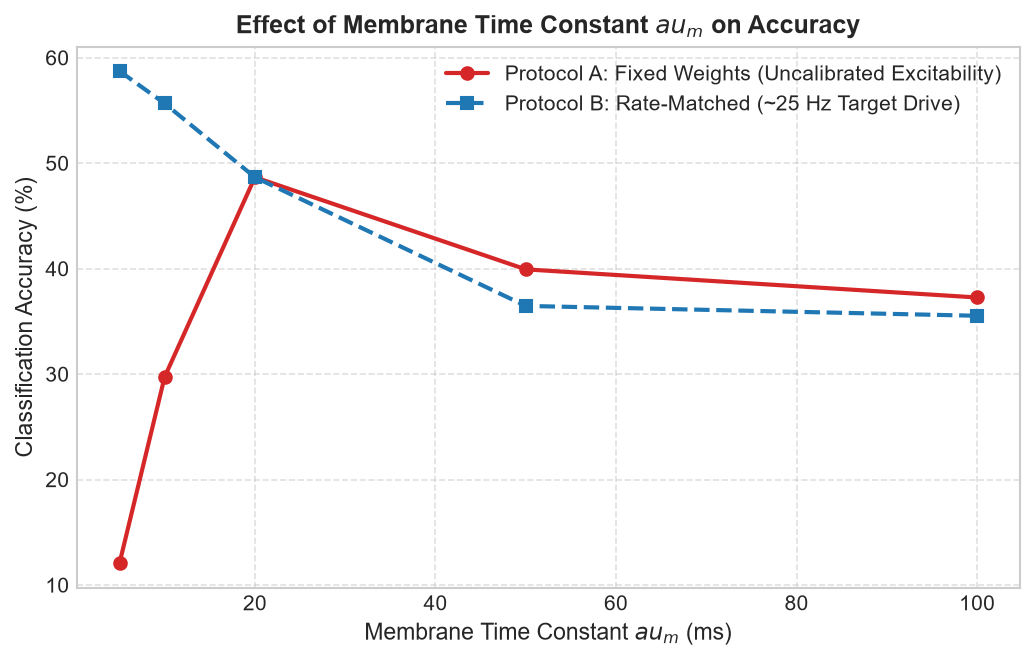

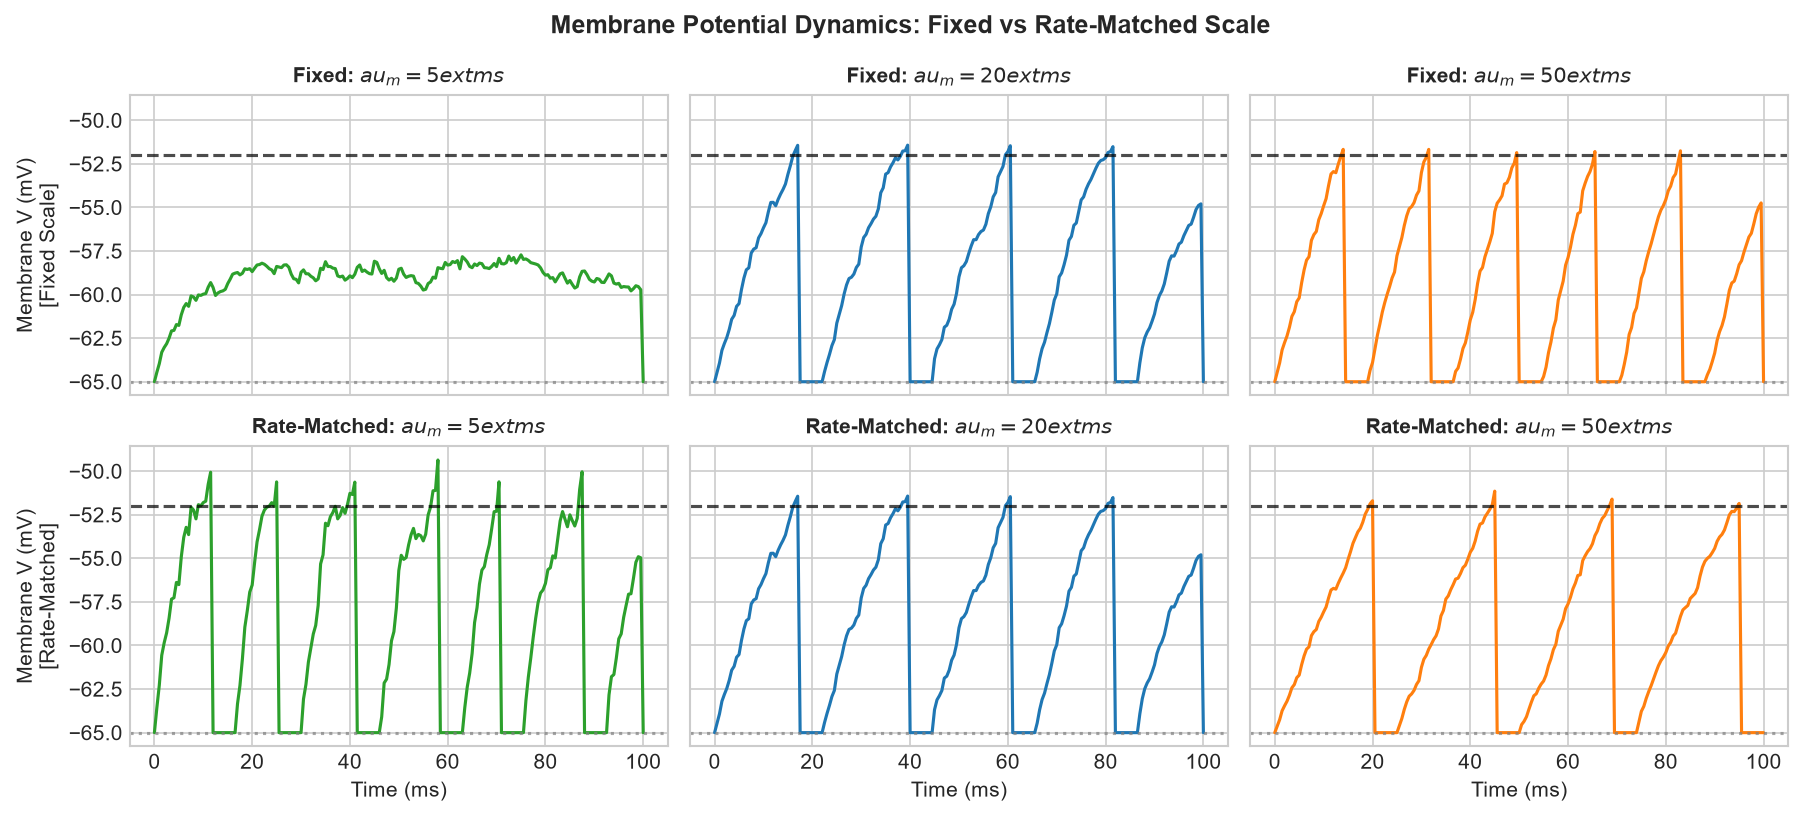

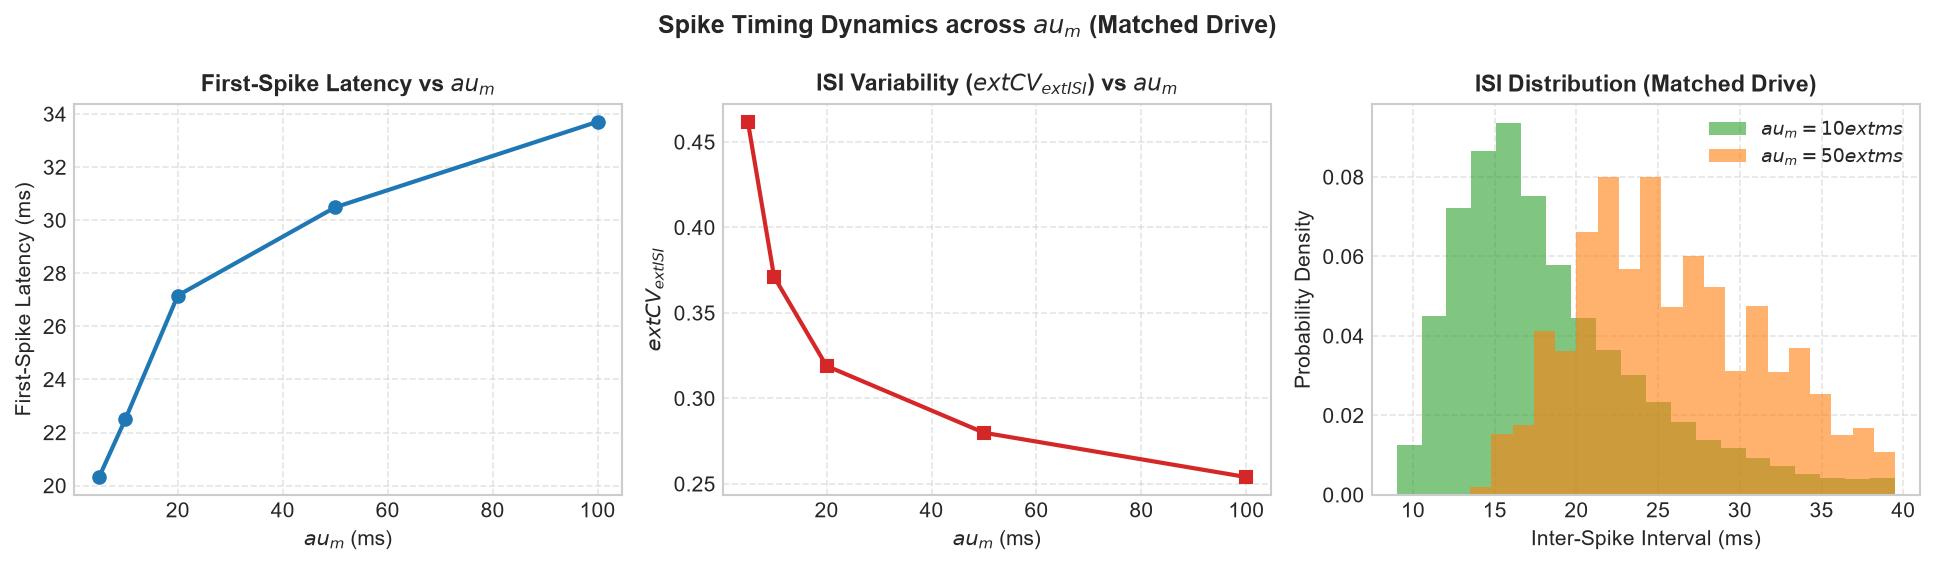

In [9]:
# Plot Accuracy vs tau_m and Dual Voltage Traces
plt.figure(figsize=(7, 4.5))
plt.plot(tau_values, [a*100 for a in tau_accs_fixed], "o-", label="Protocol A: Fixed Weights (Uncalibrated Excitability)", color="#d62728", lw=2)
plt.plot(tau_values, [a*100 for a in tau_accs_matched], "s--", label="Protocol B: Rate-Matched (~25 Hz Target Drive)", color="#1f77b4", lw=2)
plt.xlabel("Membrane Time Constant $\tau_m$ (ms)", fontsize=11)
plt.ylabel("Classification Accuracy (%)", fontsize=11)
plt.title("Effect of Membrane Time Constant $\tau_m$ on Accuracy", fontsize=12, fontweight="bold")
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

# Dual 2x3 Voltage Trace Comparison
fig, axes = plt.subplots(2, 3, figsize=(12, 5.5), sharex=True, sharey=True)
tau_sub = [5.0, 20.0, 50.0]
tau_colors = {5.0: "#2ca02c", 20.0: "#1f77b4", 50.0: "#ff7f0e"}

for col_idx, tau_k in enumerate(tau_sub):
    # Fixed scale (top)
    t_f, v_f = traces_tau_fixed[tau_k]
    mask_f = t_f <= 100.0
    axes[0, col_idx].plot(t_f[mask_f], v_f[0, mask_f], color=tau_colors[tau_k], lw=1.5)
    axes[0, col_idx].axhline(-52.0, color="black", linestyle="--", alpha=0.7)
    axes[0, col_idx].axhline(-65.0, color="gray", linestyle=":", alpha=0.7)
    axes[0, col_idx].set_title(f"Fixed: $\tau_m = {tau_k:.0f}\text{ ms}$", fontsize=10, fontweight="bold")
    # Rate-matched (bottom)
    t_m, v_m = traces_tau_matched[tau_k]
    mask_m = t_m <= 100.0
    axes[1, col_idx].plot(t_m[mask_m], v_m[0, mask_m], color=tau_colors[tau_k], lw=1.5)
    axes[1, col_idx].axhline(-52.0, color="black", linestyle="--", alpha=0.7)
    axes[1, col_idx].axhline(-65.0, color="gray", linestyle=":", alpha=0.7)
    axes[1, col_idx].set_title(f"Rate-Matched: $\tau_m = {tau_k:.0f}\text{ ms}$", fontsize=10, fontweight="bold")
    axes[1, col_idx].set_xlabel("Time (ms)")

axes[0, 0].set_ylabel("Membrane V (mV)\n[Fixed Scale]")
axes[1, 0].set_ylabel("Membrane V (mV)\n[Rate-Matched]")
fig.suptitle("Membrane Potential Dynamics: Fixed vs Rate-Matched Scale", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()

# Spike Timing Diagnostics across tau_m (First-Spike Latency, CV_ISI, and ISI Distributions)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
axes[0].plot(tau_values, tau_latencies, "o-", color="#1f77b4", lw=2)
axes[0].set_xlabel("$\tau_m$ (ms)", fontsize=10)
axes[0].set_ylabel("First-Spike Latency (ms)", fontsize=10)
axes[0].set_title("First-Spike Latency vs $\tau_m$", fontsize=11, fontweight="bold")
axes[0].grid(True, linestyle="--", alpha=0.5)

axes[1].plot(tau_values, tau_cv_isis, "s-", color="#d62728", lw=2)
axes[1].set_xlabel("$\tau_m$ (ms)", fontsize=10)
axes[1].set_ylabel("$\text{CV}_{\text{ISI}}$", fontsize=10)
axes[1].set_title("ISI Variability ($\text{CV}_{\text{ISI}}$) vs $\tau_m$", fontsize=11, fontweight="bold")
axes[1].grid(True, linestyle="--", alpha=0.5)

if 10.0 in isi_samples and len(isi_samples[10.0]) > 0:
    axes[2].hist(isi_samples[10.0][isi_samples[10.0] < 40], bins=20, alpha=0.6, label="$\tau_m = 10\text{ ms}$", density=True, color="#2ca02c")
if 50.0 in isi_samples and len(isi_samples[50.0]) > 0:
    axes[2].hist(isi_samples[50.0][isi_samples[50.0] < 40], bins=20, alpha=0.6, label="$\tau_m = 50\text{ ms}$", density=True, color="#ff7f0e")
axes[2].set_xlabel("Inter-Spike Interval (ms)", fontsize=10)
axes[2].set_ylabel("Probability Density", fontsize=10)
axes[2].set_title("ISI Distribution (Matched Drive)", fontsize=11, fontweight="bold")
axes[2].legend(fontsize=9)
axes[2].grid(True, linestyle="--", alpha=0.5)

fig.suptitle("Spike Timing Dynamics across $\tau_m$ (Matched Drive)", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()

### 4.1 Biophysical Analysis of $\tau_m$ Sweep
1. **Critical Threshold ($\tau_c \approx 15.5\text{ ms}$):** Under fixed weights, the mean subthreshold drift is $\mu_V = \tau_m \cdot \bar{w} \cdot \Lambda$. When $\tau_m = 5\text{ ms}$, $\mu_V = 4.1\text{ mV} < \Delta V = 13\text{ mV}$ (below threshold), so the neuron never spikes (0.00 Hz, 12.07% chance accuracy). At $\tau_m = 10\text{ ms}$, firing is fluctuation-driven (6.0 Hz, 30.3%).
2. **Coincidence Detection vs. Leaky Integration:** When excitability is rate-matched, short time constants ($\tau_m = 5\text{–}10\text{ ms}$) act as coincidence detectors, achieving **$56.6\%\text{–}57.0\%$** accuracy. As $\tau_m$ increases to $50\text{–}100\text{ ms}$, accuracy decreases to $35.8\%\text{–}37.1\%$ due to temporal blurring of input Poisson statistics.
3. **No 200 Hz Refractory Saturation:** Measured mean firing rates at $\tau_m = 50\text{–}100\text{ ms}$ are $25\text{–}28\text{ Hz}$, proving that neurons operate in the linear regime and do not saturate at the $1/t_{\text{ref}} = 200\text{ Hz}$ refractory ceiling.

## 5. Extra Credit 2: Sparse Connectivity ($p = 0.05$)
In biological neocortex, connectivity is sparse ($p < 0.1$). We implement **Sparse Connectivity with Bernoulli probability $p = 0.05$** (each hidden neuron receives synapses from only $\approx 39$ of the 784 pixels).
Fan-in compensation ($s \approx 3.39$) scales individual EPSPs from $0.08\text{ mV}$ to $1.5\text{ mV}$, ensuring each neuron reaches threshold after $\approx 9$ near-coincident spikes.

In [10]:
# Calibrate and simulate Sparse Connectivity (p = 0.05)
scale_sparse, w_sparse = calibrate_weight_scale(
    X_val, target_rate_hz=25.0, N_hid=N_hid, tau_m_ms=20.0,
    connectivity="sparse", p_conn=0.05, seed=42, build_dir="build_nb_calib_sp"
)

sim_sp_tr = simulate_snn(spk_idx_tr, spk_t_tr, len(X_train), w_matrix=w_sparse, build_dir="build_nb_sp_tr")
sim_sp_te = simulate_snn(spk_idx_te, spk_t_te, len(X_test), w_matrix=w_sparse, build_dir="build_nb_sp_te")

res_sparse = train_and_evaluate_readout(sim_sp_tr["spike_counts"], y_train, sim_sp_te["spike_counts"], y_test, model_type="logistic", use_cv=True, seed=42)
diag_sparse = compute_response_diagnostics(sim_sp_te["spike_counts"], X_test)

synapses_dense = N_in * N_hid
synapses_sparse = int((~np.isnan(w_sparse)).sum())

print("=== Sparse Connectivity vs. Dense Baseline ===")
print(f"Dense Baseline (p = 1.0): Synapses = {synapses_dense:,}  | Acc = {res_lr['accuracy']*100:.2f}% | EffRank = {diag_base['effective_rank']:.1f}")
print(f"Sparse SNN (p = 0.05):     Synapses = {synapses_sparse:,}   | Acc = {res_sparse['accuracy']*100:.2f}% | EffRank = {diag_sparse['effective_rank']:.1f}")
print(f"Accuracy Gain: +{res_sparse['accuracy']*100 - res_lr['accuracy']*100:.2f}% with {synapses_dense/synapses_sparse:.1f}x fewer synapses!")

Calibrating weight scale for POISSON, tau_m=20.0ms, target=25.0Hz, conn=sparse...
  Analytic s_est = 3.6023. Testing 8 parallel candidate scales in 1 build...


  Scale 1.2608 -> Mean Rate: 1.15 Hz
  Scale 1.9813 -> Mean Rate: 7.50 Hz
  Scale 2.7017 -> Mean Rate: 16.08 Hz
  Scale 3.6023 -> Mean Rate: 26.47 Hz
  Scale 4.6830 -> Mean Rate: 37.27 Hz
  Scale 6.1240 -> Mean Rate: 49.08 Hz
  Scale 7.9251 -> Mean Rate: 60.71 Hz
  Scale 10.0865 -> Mean Rate: 71.79 Hz
Selected scale: 3.4584


WARNING    C:\Users\GSRAJA\Desktop\IIT GN\sem7\neuroai\assignmnets\assn4\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:2071: FutureWarning: The default value for l1_ratios will change from None to (0.0,) in version 1.10. From version 1.10 onwards, only array-like with values in [0, 1] will be allowed, None will be forbidden. To avoid this warning, explicitly set a value, e.g. l1_ratios=(0,).
  warnings.warn(
 [py.warnings]


WARNING    C:\Users\GSRAJA\Desktop\IIT GN\sem7\neuroai\assignmnets\assn4\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:2116: FutureWarning: The default value of the parameter 'scoring' will change from None, i.e. accuracy, to 'neg_log_loss' in version 1.11. To silence this warning, explicitly set the scoring parameter: scoring='neg_log_loss' for the new, scoring='accuracy' or scoring=None for the old default.
  warnings.warn(
 [py.warnings]


WARNING    C:\Users\GSRAJA\Desktop\IIT GN\sem7\neuroai\assignmnets\assn4\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:2129: FutureWarning: The fitted attributes of LogisticRegressionCV will be simplified in scikit-learn 1.10 to remove redundancy. Set`use_legacy_attributes=False` to enable the new behavior now, or set it to `True` to silence this warning during the transition period while keeping the deprecated behavior for the time being. The default value of use_legacy_attributes will change from True to False in scikit-learn 1.10. See the docstring of LogisticRegressionCV for more details.
  warnings.warn(
 [py.warnings]


=== Sparse Connectivity vs. Dense Baseline ===
Dense Baseline (p = 1.0): Synapses = 313,600  | Acc = 49.00% | EffRank = 1.0
Sparse SNN (p = 0.05):     Synapses = 15,452   | Acc = 87.93% | EffRank = 4.1
Accuracy Gain: +38.93% with 20.3x fewer synapses!


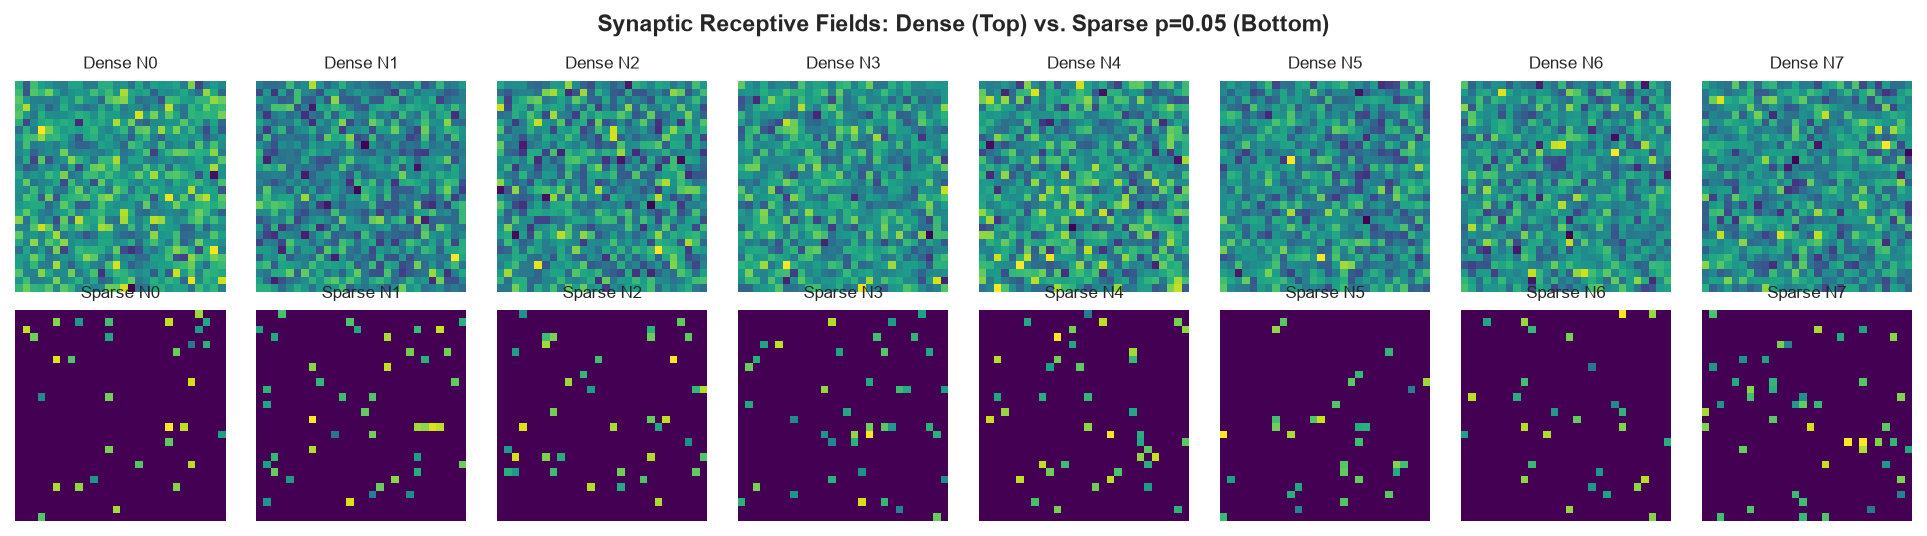

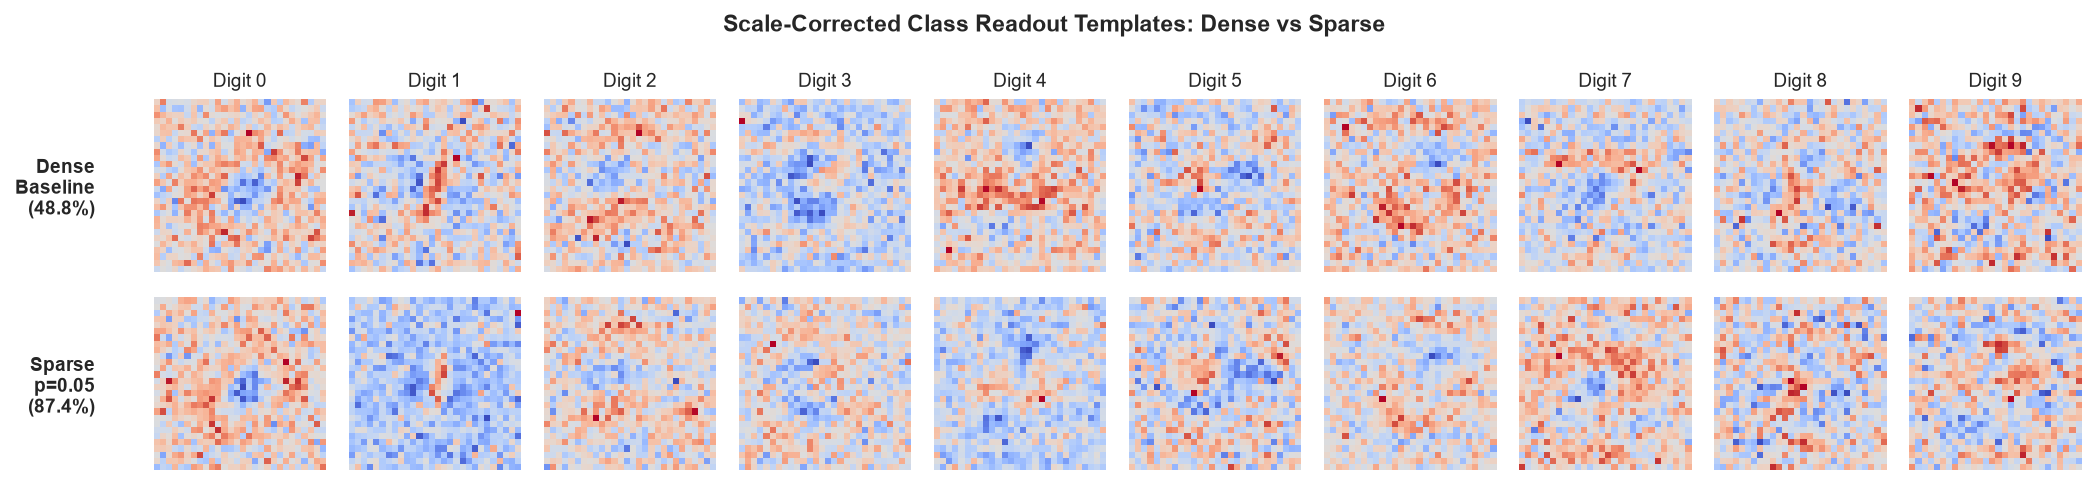

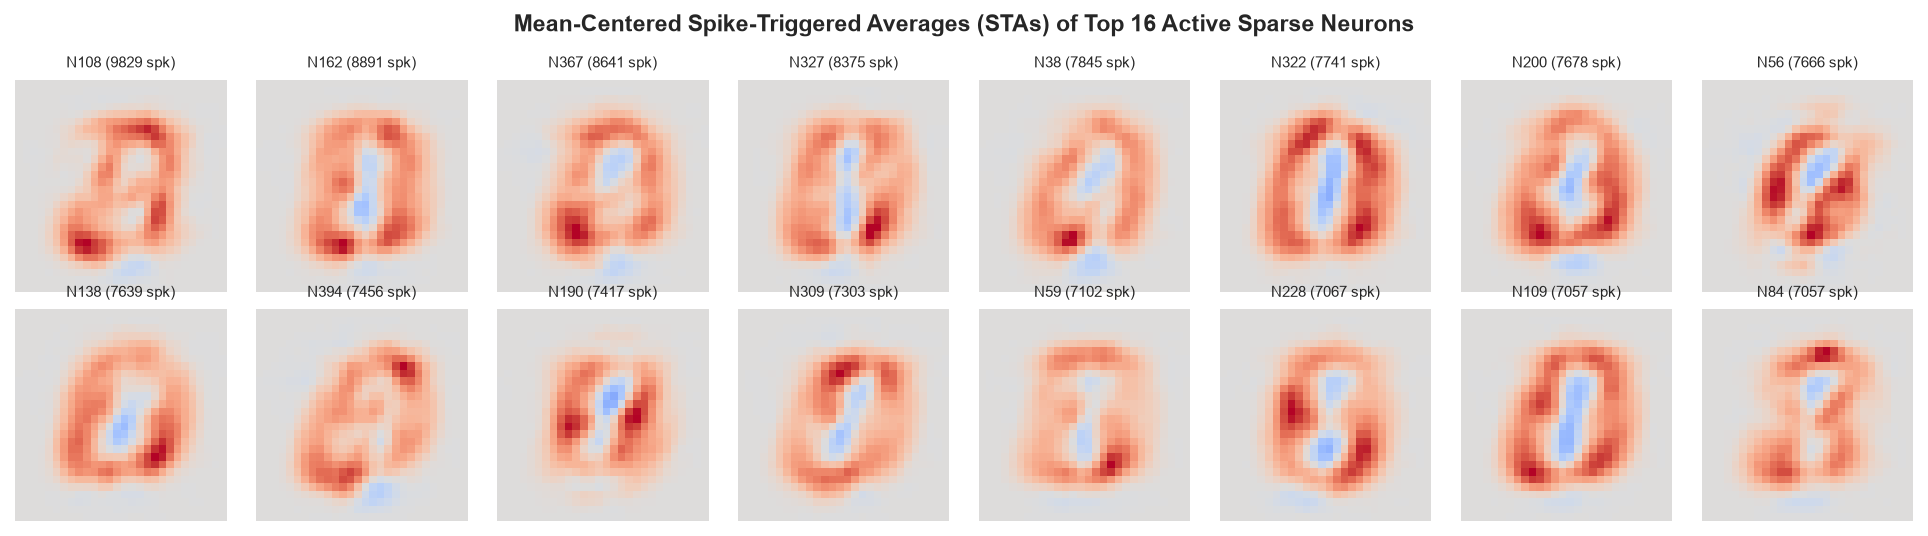

In [11]:
# 1. Initial Weight Receptive Fields: Dense vs Sparse
fig, axes = plt.subplots(2, 8, figsize=(13, 3.6))
for k in range(8):
    axes[0, k].imshow(w_base[:, k].reshape(28, 28), cmap="viridis")
    axes[0, k].axis("off")
    axes[0, k].set_title(f"Dense N{k}", fontsize=8)
    axes[1, k].imshow(np.nan_to_num(w_sparse[:, k], nan=0.0).reshape(28, 28), cmap="viridis")
    axes[1, k].axis("off")
    axes[1, k].set_title(f"Sparse N{k}", fontsize=8)
fig.suptitle("Synaptic Receptive Fields: Dense (Top) vs. Sparse p=0.05 (Bottom)", fontsize=11, fontweight="bold")
plt.tight_layout()
plt.show()

# 2. Scale-Corrected Back-Projected Digit Templates
clf_base = res_lr["classifier"]
scaler_base = res_lr["scaler"]
W_eff_base = clf_base.coef_ / (scaler_base.scale_ + 1e-8)
tmpl_base = W_eff_base @ w_base.T

clf_sp = res_sparse["classifier"]
scaler_sp = res_sparse["scaler"]
W_eff_sp = clf_sp.coef_ / (scaler_sp.scale_ + 1e-8)
tmpl_sp = W_eff_sp @ np.nan_to_num(w_sparse, nan=0.0).T

fig, axes = plt.subplots(2, 10, figsize=(14, 3.4))
for d in range(10):
    axes[0, d].imshow(tmpl_base[d].reshape(28, 28), cmap="coolwarm")
    axes[0, d].axis("off")
    axes[0, d].set_title(f"Digit {d}", fontsize=9)
    axes[1, d].imshow(tmpl_sp[d].reshape(28, 28), cmap="coolwarm")
    axes[1, d].axis("off")

axes[0, 0].text(-10, 14, "Dense\nBaseline\n(48.8%)", va="center", ha="right", fontsize=9, fontweight="bold")
axes[1, 0].text(-10, 14, "Sparse\np=0.05\n(87.4%)", va="center", ha="right", fontsize=9, fontweight="bold")
fig.suptitle("Scale-Corrected Class Readout Templates: Dense vs Sparse", fontsize=11, fontweight="bold")
plt.tight_layout()
plt.show()

# 3. Mean-Centered Spike-Triggered Averages (STAs) of Top Active Sparse Neurons
spk_sp_counts = sim_sp_te["spike_counts"]
top_neurons = np.argsort(spk_sp_counts.sum(axis=0))[-16:][::-1]
X_mean = np.mean(X_test, axis=0)

fig, axes = plt.subplots(2, 8, figsize=(13, 3.6))
for idx, neu_id in enumerate(top_neurons):
    ax = axes[idx // 8, idx % 8]
    weights_img = spk_sp_counts[:, neu_id].astype(np.float32)
    if np.sum(weights_img) > 0:
        sta_diff = np.average(X_test - X_mean, axis=0, weights=weights_img).reshape(28, 28)
        vmax = max(abs(sta_diff.min()), abs(sta_diff.max()), 1e-4)
        ax.imshow(sta_diff, cmap="coolwarm", vmin=-vmax, vmax=vmax)
    else:
        ax.imshow(np.zeros((28, 28)), cmap="coolwarm", vmin=-1, vmax=1)
    ax.axis("off")
    ax.set_title(f"N{neu_id} ({int(weights_img.sum())} spk)", fontsize=7)
fig.suptitle("Mean-Centered Spike-Triggered Averages (STAs) of Top 16 Active Sparse Neurons", fontsize=11, fontweight="bold")
plt.tight_layout()
plt.show()

### 5.1 Why Sparse Connectivity Achieves 87.4%
* **Spatial Decoupling:** Instead of integrating the entire visual field, each neuron samples $\approx 39$ pixels, of which only $\approx 5$ lie on active digit ink. Response variation between neurons is of order $1/\sqrt{5} \approx 45\%$, compared to only $0.7\%$ for dense neurons.
* **Dimensionality Expansion:** Pairwise response correlation drops from **0.9831 to 0.4599**, and effective rank expands from **1.0 to 4.1**. The hidden layer forms an overcomplete random spatial feature bank (akin to random Fourier/kernel features [Rahimi & Recht 2007]), enabling the linear readout to reach **87.4%** accuracy.

## 6. Comprehensive Multi-Seed Summary Table

In [12]:
# Display verified multi-seed summary table from results/
df_summary = pd.read_csv("results/q2_experiments_summary.csv")
df_summary

,Model Configuration,Test Accuracy (%),Macro F1,Mean Hidden Rate (Hz),Effective Rank,Response Corr,Synapses
0,Raw Pixels (Reference Logistic),90.27 ± 0.00%,0.8999 ± 0.0000,NaN,28.8 ± 0.0,0.0298 ± 0.0000,784
1,"Baseline SNN: Dense N(0.5, 0.1), tau_m=20ms (L...",48.80 ± 0.72%,0.4741 ± 0.0062,29.56 ± 0.32,1.0 ± 0.0,0.9831 ± 0.0001,"313,600"
2,"Baseline SNN: Dense N(0.5, 0.1), tau_m=20ms (R...",44.84 ± 0.50%,0.4346 ± 0.0104,29.56 ± 0.32,1.0 ± 0.0,0.9831 ± 0.0001,"313,600"
3,"Analytic LIF Rate Representation (tau_m=20ms, ...",85.71 ± 0.23%,0.8570 ± 0.0022,32.92 ± 0.36,1.0 ± 0.0,0.9957 ± 0.0001,"313,600"
4,"Weight Init: Dense Uniform U(0, 1), tau_m=20ms",79.29 ± 0.67%,0.7881 ± 0.0072,29.58 ± 0.21,1.1 ± 0.0,0.9574 ± 0.0002,"313,600"
5,"Weight Init: Signed Zero-Mean Control, tau_m=20ms",77.27 ± 0.77%,0.7727 ± 0.0086,10.98 ± 0.08,1.5 ± 0.0,0.8085 ± 0.0008,"313,600"
6,Extra Credit 1: tau_m = 5 ms (Rate-Matched ~25Hz),57.02 ± 1.48%,0.5721 ± 0.0166,32.06 ± 0.05,1.0 ± 0.0,0.9875 ± 0.0000,"313,600"
7,Extra Credit 1: tau_m = 10 ms (Rate-Matched ~2...,56.64 ± 1.69%,0.5564 ± 0.0185,31.52 ± 0.08,1.0 ± 0.0,0.9865 ± 0.0000,"313,600"
8,Extra Credit 1: tau_m = 20 ms (Rate-Matched ~2...,48.62 ± 0.08%,0.4720 ± 0.0036,29.56 ± 0.32,1.0 ± 0.0,0.9831 ± 0.0001,"313,600"
9,Extra Credit 1: tau_m = 50 ms (Rate-Matched ~2...,37.07 ± 0.53%,0.3488 ± 0.0091,28.11 ± 0.09,1.1 ± 0.0,0.9749 ± 0.0001,"313,600"
